# 03 · 订多少货：报童模型与方法 D

notebook 02 衡量的是预测误差（件）。门店更关心的是：按照这个预测订货，**会损失多少钱**。

1. 设定价格，计算临界比率 CR。
2. 方法 A、B、C：订货量 = 预测值 + 安全库存（`Q = μ + z·σ`）。
3. 方法 D：分位数 LightGBM 直接给出订货量。
4. 在 2017 年上计算损失（元）、服务水平和不缺货周数占比。
5. 敏感性分析：CR = 0.5 / 0.67 / 0.8 / 0.9。
6. 图表。

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.stats import norm
from pathlib import Path

DATA = Path("../data")
FIG = Path("../figures")

fc = pd.read_csv(DATA / "forecasts.csv", parse_dates=["week"])
print(fc.shape)
fc.head()

(52000, 8)


,week,store,item,split,sales,pred_A,pred_B,pred_C
0,2016-01-04,1,1,valid,106,103.00,108.0,115.211743
1,2016-01-11,1,1,valid,81,100.25,89.0,94.088448
2,2016-01-18,1,1,valid,108,93.75,95.0,99.734156
3,2016-01-25,1,1,valid,108,97.50,93.0,97.834457
4,2016-02-01,1,1,valid,106,100.75,86.0,90.583126


## 1. 价格与临界比率

数据中没有价格，以下为假设值（之后做敏感性分析）：
- 售价 `p` = 10 元，进价 `c` = 4 元，残值 `v` = 1 元（卖不掉的每件只能收回 1 元）。

因此：
- `cu = p − c = 6`：每**缺**一件损失 6 元；
- `co = c − v = 3`：每**多**一件损失 3 元；
- `CR = cu / (cu + co) = 6 / 9 ≈ 0.67`：订货量应使约 67% 的周不缺货。

In [23]:
p, c, v = 10, 4, 1
cu = p - c          # 缺货成本
co = c - v          # 剩余成本
CR = cu / (cu + co)
z = norm.ppf(CR)    # 标准正态分布的 CR 分位数
print(f"cu = {cu}, co = {co}, CR = {CR:.3f}, z = {z:.3f}")

cu = 6, co = 3, CR = 0.667, z = 0.431


## 2. 方法 A、B、C：订货量 = 预测 + z·σ

**σ** 表示预测通常会错多少。对每个“门店 × 商品”分别用 2016 年验证集上的预测误差计算标准差：卖 1000 件的商品误差比卖 100 件的大。

2017 年：`Q = 预测 + z × σ`，取整，且不小于 0。

例：预测 112，σ = 18.6，z = 0.43 → Q = 112 + 0.43 × 18.6 ≈ 120。

In [24]:
METHODS = {"A": "pred_A", "B": "pred_B", "C": "pred_C"}

val = fc[fc["split"] == "valid"]
test = fc[fc["split"] == "test"].copy()

sigma = {}
for m, col in METHODS.items():
    err = val[col] - val["sales"]
    sigma[m] = err.groupby([val["store"], val["item"]]).std().rename(f"sigma_{m}")
    test = test.merge(sigma[m], left_on=["store", "item"], right_index=True)

for m, col in METHODS.items():
    test[f"Q_{m}"] = np.maximum(0, np.round(test[col] + z * test[f"sigma_{m}"]))

# 对照：订货量 = C 的预测值，不加安全库存
test["Q_C_plain"] = np.maximum(0, np.round(test["pred_C"]))

test[["week", "store", "item", "sales", "pred_C", "sigma_C", "Q_C", "Q_C_plain"]].head()

,week,store,item,sales,pred_C,sigma_C,Q_C,Q_C_plain
52,2017-01-02,1,1,113,112.381389,18.617478,120.0,112.0
53,2017-01-09,1,1,112,87.802159,18.617478,96.0,88.0
54,2017-01-16,1,1,111,118.512705,18.617478,127.0,119.0
55,2017-01-23,1,1,104,115.851673,18.617478,124.0,116.0
56,2017-01-30,1,1,132,111.882555,18.617478,120.0,112.0


## 3. 方法 D：分位数 LightGBM

普通模型预测“中间值”。α = 0.67 的**分位数**模型预测的是：需求在 67% 的情况下不会超过的量，这正是报童模型的最优订货量，不需要单独计算 σ。

特征和 `sales / lag52` 的做法与 notebook 02 相同。lag52 事先已知，所以比值的分位数 × lag52 就是销量的分位数。

用 2014–2016 年训练（与最终的方法 C 相同），预测 2017 年。

In [25]:
weekly = pd.read_csv(DATA / "weekly.csv", parse_dates=["week"])
weekly = weekly.sort_values(["store", "item", "week"]).reset_index(drop=True)
g = weekly.groupby(["store", "item"])["sales"]
weekly["lag52"] = g.shift(52)
weekly["roll4"] = g.transform(lambda s: s.shift(1).rolling(4).mean())
weekly["roll4_ly"] = g.transform(lambda s: s.shift(53).rolling(4).mean())
weekly["week_of_year"] = weekly["week"].dt.isocalendar().week.astype(int).clip(upper=52)
weekly["month"] = weekly["week"].dt.month
weekly["growth_recent"] = weekly["roll4"] / weekly["roll4_ly"]
weekly["ratio"] = weekly["sales"] / weekly["lag52"]
for col in ["store", "item"]:
    weekly[col] = weekly[col].astype("category")

FEATURES = ["growth_recent", "week_of_year", "month", "store", "item"]
ok = weekly[FEATURES + ["lag52", "roll4_ly"]].notna().all(axis=1)
fit_part = weekly[ok & weekly["split"].isin(["train", "valid"])]
test_part = weekly[ok & (weekly["split"] == "test")]

def quantile_order(alpha):
    """训练分位数 LightGBM，返回 2017 年的订货量。"""
    model = lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=400,
                              learning_rate=0.05, num_leaves=31, min_child_samples=50,
                              random_state=42, verbose=-1)
    model.fit(fit_part[FEATURES], fit_part["ratio"])
    q = model.predict(test_part[FEATURES]) * test_part["lag52"]
    out = test_part[["week", "store", "item"]].copy()
    out["Q_D"] = np.maximum(0, np.round(q.values))
    out["store"] = out["store"].astype(int)
    out["item"] = out["item"].astype(int)
    return out

test = test.merge(quantile_order(CR), on=["week", "store", "item"])
print("测试集行数:", len(test))

测试集行数: 26000


## 4. 损失、服务水平、不缺货周数

对每个“周 × 门店 × 商品”：
- 缺了 `max(D − Q, 0)` 件 → 每件损失 `cu`；
- 剩了 `max(Q − D, 0)` 件 → 每件损失 `co`。

**服务水平（满足率）** = 满足的需求 / 全部需求。想买 100 件、只有 92 件 → 92%。

**不缺货周数占比** = Q ≥ D 的周所占比例。报童公式的目标是 CR ≈ 66.7%。

In [26]:
def evaluate(df, Q_col, cu, co):
    D, Q = df["sales"], df[Q_col]
    short = np.maximum(D - Q, 0)
    over = np.maximum(Q - D, 0)
    return {
        "总损失（千元）": (cu * short + co * over).sum() / 1000,
        "其中缺货": cu * short.sum() / 1000,
        "其中剩余": co * over.sum() / 1000,
        "服务水平（%）": 100 * np.minimum(D, Q).sum() / D.sum(),
        "不缺货周数占比（%）": 100 * (Q >= D).mean(),
    }

ORDERS = {
    "A. 移动平均 + 报童公式": "Q_A",
    "B. 季节性朴素法 + 报童公式": "Q_B",
    "C. LightGBM + 报童公式": "Q_C",
    "C. LightGBM，订货量 = 预测值": "Q_C_plain",
    "D. 分位数 LightGBM": "Q_D",
}
LABELS_EN = {
    "A. 移动平均 + 报童公式": "A: 4-week average + z·σ",
    "B. 季节性朴素法 + 报童公式": "B: last year + z·σ",
    "C. LightGBM + 报童公式": "C: LightGBM + z·σ",
    "C. LightGBM，订货量 = 预测值": "C: LightGBM, order = forecast",
    "D. 分位数 LightGBM": "D: quantile LightGBM",
}

main = pd.DataFrame({name: evaluate(test, col, cu, co) for name, col in ORDERS.items()}).T
main["相对 A（%）"] = 100 * main["总损失（千元）"] / main.loc["A. 移动平均 + 报童公式", "总损失（千元）"]
main = main.round(1)
main

,总损失（千元）,其中缺货,其中剩余,服务水平（%）,不缺货周数占比（%）,相对 A（%）
A. 移动平均 + 报童公式,3159.5,1272.6,1887.0,98.0,64.4,100.0
B. 季节性朴素法 + 报童公式,2762.2,1998.8,763.4,96.9,47.7,87.4
C. LightGBM + 报童公式,2670.3,553.3,2117.0,99.1,78.9,84.5
C. LightGBM，订货量 = 预测值,2523.5,1175.4,1348.1,98.2,63.3,79.9
D. 分位数 LightGBM,2698.8,588.4,2110.4,99.1,78.3,85.4


**解读：**
- 最重要的是**总损失**，越小越好；“相对 A”表示损失是方法 A 的百分之多少。
- “C，订货量 = 预测值”一行用来检验报童公式本身是否省钱：同一个预测，不加安全库存会怎样。
- 报童公式假设预测无偏。预测有偏差时，不缺货周数会偏离 66.7% 的目标。

## 5. 敏感性分析

价格是假设的。保持 `co = 3`，改变 `cu`，使 CR = 0.5 / 0.67 / 0.8 / 0.9。每个 CR 都重新计算 z，并重新训练方法 D 的分位数模型（约 1 分钟）。

In [27]:
rows = []
for cr in [0.5, 2/3, 0.8, 0.9]:
    cu_s = co * cr / (1 - cr)        # 由 CR = cu / (cu + co) 反推 cu
    z_s = norm.ppf(cr)
    tmp = test[["week", "store", "item", "sales"]].copy()
    for m, col in METHODS.items():
        tmp[f"Q_{m}"] = np.maximum(0, np.round(test[col] + z_s * test[f"sigma_{m}"]))
    tmp = tmp.merge(quantile_order(cr), on=["week", "store", "item"])
    for m in ["A", "B", "C", "D"]:
        r = evaluate(tmp, f"Q_{m}", cu_s, co)
        rows.append({"CR": round(cr, 2), "method": m, "loss": r["总损失（千元）"],
                     "service": r["服务水平（%）"]})

sens = pd.DataFrame(rows)
sens["loss_vs_A"] = 100 * sens["loss"] / sens.groupby("CR")["loss"].transform(lambda s: s.iloc[0])
sens.pivot(index="CR", columns="method", values="loss_vs_A").round(1)

method,A,B,C,D
CR,,,,
0.50,100.0,83.1,80.5,80.5
0.67,100.0,87.4,84.5,85.4
0.80,100.0,91.9,88.2,90.1
0.90,100.0,97.0,91.3,94.1


表中为各方法的损失占同一 CR 下方法 A 损失的百分比。如果每一行的排序都相同，说明结论是**稳健**的。CR = 0.5 时 z = 0，方法 C 等于预测中位数，与 α = 0.5 的方法 D 在理论上等价。

## 6. 图表

**图 1：** 单条序列 2017 年的实际需求与方法 A、D 的订货量。

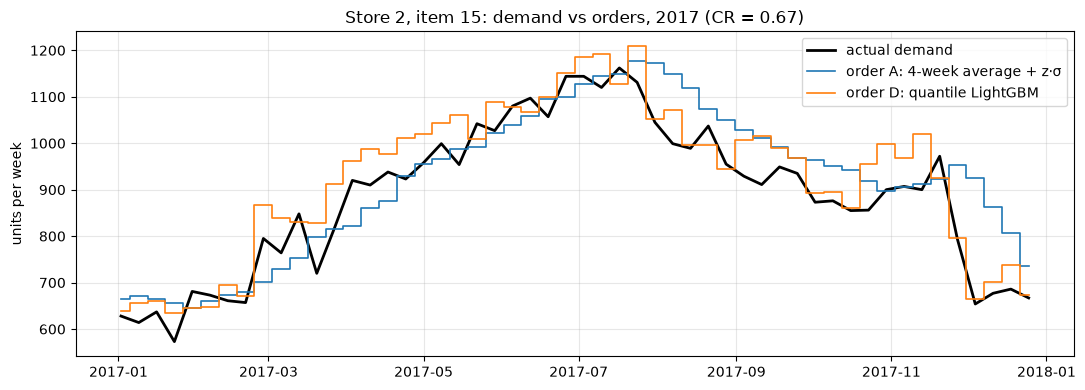

In [28]:
one = test[(test["store"] == 2) & (test["item"] == 15)].sort_values("week")
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(one["week"], one["sales"], color="black", lw=2, label="actual demand")
ax.step(one["week"], one["Q_A"], where="mid", lw=1.2, label="order A: 4-week average + z·σ")
ax.step(one["week"], one["Q_D"], where="mid", lw=1.2, label="order D: quantile LightGBM")
ax.set_title(f"Store 2, item 15: demand vs orders, 2017 (CR = {CR:.2f})")
ax.set_ylabel("units per week")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "03_orders_one_series.png", dpi=150)
plt.show()

**图 2：** 各方法的损失构成：缺货与剩余。

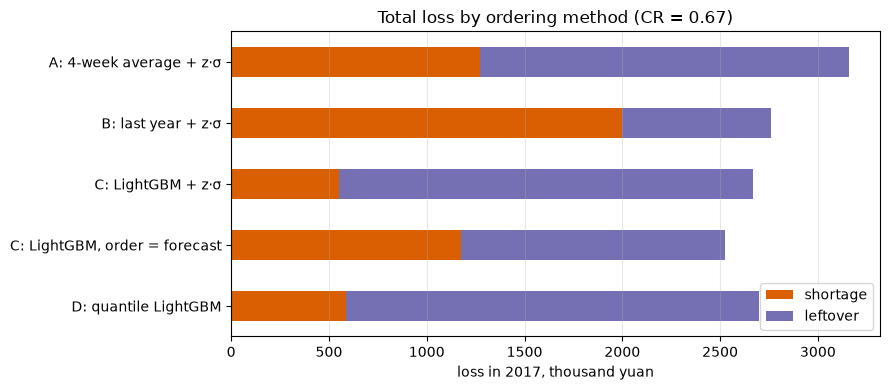

In [29]:
plot_df = main[["其中缺货", "其中剩余"]].iloc[::-1].rename(index=LABELS_EN)
fig, ax = plt.subplots(figsize=(9, 4))
plot_df.plot.barh(stacked=True, ax=ax, color=["#d95f02", "#7570b3"])
ax.set_xlabel("loss in 2017, thousand yuan")
ax.set_title(f"Total loss by ordering method (CR = {CR:.2f})")
ax.legend(["shortage", "leftover"])
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "03_loss_by_method.png", dpi=150)
plt.show()

**图 3：** 敏感性分析：不同 CR 下各方法损失相对方法 A 的百分比。

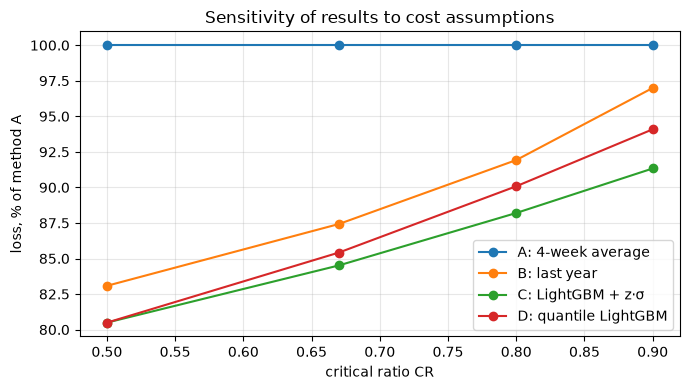

In [30]:
fig, ax = plt.subplots(figsize=(7, 4))
for m, label in [("A", "A: 4-week average"), ("B", "B: last year"),
                 ("C", "C: LightGBM + z·σ"), ("D", "D: quantile LightGBM")]:
    s = sens[sens["method"] == m]
    ax.plot(s["CR"], s["loss_vs_A"], marker="o", label=label)
ax.set_xlabel("critical ratio CR")
ax.set_ylabel("loss, % of method A")
ax.set_title("Sensitivity of results to cost assumptions")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "03_sensitivity.png", dpi=150)
plt.show()

## 7. 保存

In [31]:
main.to_csv(DATA / "newsvendor_results.csv")
sens.to_csv(DATA / "sensitivity.csv", index=False)
test.to_csv(DATA / "orders_test.csv", index=False)
print("已保存: newsvendor_results.csv, sensitivity.csv, orders_test.csv")

已保存: newsvendor_results.csv, sensitivity.csv, orders_test.csv


## 小结

- 在事先设定的方法中，“C + 报童公式”损失最小，比方法 A 低约 15%。
- 方法 A 的预测几乎无偏，不缺货周数占比（64.4%）接近目标（66.7%）。LightGBM 在测试期高估需求，再加上安全库存导致库存偏多，所以“C + 报童公式”比“订货量 = 预测值”损失更高；后者是看到测试结果后才知道的，不作为最终方法。
- MAE 对高估和低估一视同仁，而缺货比剩余贵一倍，所以评价库存决策要看决策成本。
- 在 CR = 0.5 / 0.67 / 0.8 / 0.9 下各方法排序不变，结论稳健。